# 4.3 การเพิ่มขึ้นเกิดขึ้นที่ไหน — การกระจายและความเหลื่อมล้ำระหว่างจังหวัด

หัวข้อ 4.1–4.2 เป็นภาพรวมระดับประเทศ หัวข้อนี้ตอบสี่คำถามบน **76 จังหวัด (ไม่รวมกรุงเทพฯ)**
1. ความเหลื่อมล้ำเปลี่ยนไปอย่างไร และอยู่ที่ระดับใดที่สังเกตได้ (ระหว่างเขตสุขภาพ / ระหว่างจังหวัดในเขตเดียวกัน)
2. การเติบโตลดช่องว่างใด — เมื่อเทียบกับประชากร ทะเบียนสิทธิ โครงสร้างอายุ บริการ และบริการคาดหมาย M5
3. จังหวัดที่ตั้งต้นต่ำกำลังตามทันหรือไม่ และการเข้าใกล้ความเท่าเทียมต้องการอะไร
4. จังหวัดที่ควรให้ความสำคัญเปลี่ยนไปหรือไม่เมื่อเปลี่ยนตัวหาร

ข้อมูลระดับจังหวัดระบุความเหลื่อมล้ำ **ภายในจังหวัด** ไม่ได้ (ไม่มีตัวหารระดับอำเภอ/สถานพยาบาลที่ใช้ได้ในโครงการ)
ดัชนีเหล่านี้บรรยายการกระจายของยอดรวมที่บันทึก จึงไม่แนบช่วงความเชื่อมั่นจากการสุ่มตัวอย่าง
ยกเว้นส่วนที่ตัวหารมาจากแบบจำลอง (ใช้ bootstrap ของ M5 จาก 4.2)

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "analysis.toml").exists())
sys.path.insert(0, str(_root / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import spearmanr
from IPython.display import display

from chapter4 import config as C, panels as P, metrics as M, reporting as R
from chapter4.ingest import load

pd.options.display.max_columns = 40
pd.options.display.width = 200
FONT = R.setup_style()
S = R.Section("4_3")
Y0, Y1 = C.Y0, C.Y1
CAD = C.CADRES
EN = C.CADRE_EN
IQ = C.CFG["inequality"]
BK = int(P.key().query("is_bangkok").prov_code.iloc[0])
KEY = P.key()[lambda d: ~d.is_bangkok].set_index("prov_code")
NAME = KEY.province.to_dict()
print(C.effective_config("4_3"))

# dependency on 4.2: the standardized denominators and the age-weight verdict (never recomputed here)
T42 = C.OUTPUTS / "chapter4_2" / "tables"
need = ["T423_M5_DENOMINATORS.csv", "T423_M5_BOOTSTRAP_E_2025.csv", "T423_AGE_WEIGHT_VERDICT.csv", "T423_AGE_WEIGHTED_POPULATION.csv", "T422_HDC_SCREEN_ROWS.csv"]
missing = [f for f in need if not (T42 / f).exists()]
if missing:
    raise FileNotFoundError(f"missing 4.2 outputs {missing} - run: python -m chapter4.build --section 4.2")
M5D = pd.read_csv(T42 / "T423_M5_DENOMINATORS.csv", encoding="utf-8-sig")
M5B = pd.read_csv(T42 / "T423_M5_BOOTSTRAP_E_2025.csv", encoding="utf-8-sig")
AGEV = pd.read_csv(T42 / "T423_AGE_WEIGHT_VERDICT.csv", encoding="utf-8-sig")
AWP = pd.read_csv(T42 / "T423_AGE_WEIGHTED_POPULATION.csv", encoding="utf-8-sig")
HDCS = pd.read_csv(T42 / "T422_HDC_SCREEN_ROWS.csv", encoding="utf-8-sig")
assert set(M5D.accepted.unique()) <= {True, False}
print("M5 denominators accepted:", M5D.groupby("outcome").accepted.first().to_dict())
print("age weight verdicts:", AGEV[AGEV.question.str.startswith("2")].set_index("outcome").decision.to_dict())

{
 "years": {
  "long_first": 2013,
  "long_last": 2025,
  "casemix_first": 2018,
  "casemix_last": 2025,
  "morbidity_first": 2022,
  "morbidity_last": 2025,
  "flow_first_fy": 2017,
  "flow_last_complete_fy": 2025,
  "recent_window_years": 5,
  "pre_transfer_last": 2022,
  "covid_years": [
   2020,
   2021,
   2022
  ]
 },
 "geography": {
  "bangkok": "กรุงเทพมหานคร",
  "provincial_exclude": [
   "กรุงเทพมหานคร"
  ]
 },
 "inequality": {
  "priority_quartile": 19,
  "near_band": 0.2,
  "gini_threshold": 0.1,
  "p90p10_threshold": 1.5,
  "horizon_years": 20,
  "lambda_share": 0.1,
  "priority_bootstrap": 500
 },
 "models": {
  "outcomes": [
   "op_moph",
   "ip_moph",
   "adjrw"
  ],
  "cv_folds": 5,
  "cv_repeats": 10,
  "cv_seed": 20260924,
  "paired_bootstrap_draws": 4000,
  "standardization_bootstrap_draws": 500,
  "reference_year": 2023,
  "positive_model_repeats": 5,
  "supply_long_first": 2013
 },
 "random_seed": 20260925
}
M5 denominators accepted: {'adjrw': True, 'ip_moph': Tr

## 0. ตารางกำลังคนและตัวหารรายจังหวัด (long format)
ตัวหารแต่ละชนิดจับคู่กับขอบเขตบุคลากรที่เหมาะสม: ตัวหารประชากรใช้ได้กับทุกสังกัดและ สธ.;
ตัวหารบริการของโรงพยาบาล สธ. และ M5 ใช้กับบุคลากร สธ. เท่านั้น; ทันตแพทย์และเภสัชกรใช้กิจกรรมเฉพาะวิชาชีพเป็นหลัก

In [2]:
panel, _ = P.province_panel()
WF = pd.concat([P.workforce_province(u).assign(scope=u) for u in ["all_sectors", "moph"]])
WF = WF[WF.prov_code != BK].rename(columns={"headcount": "W"})
assert WF.W.notna().all()
S.claim("c43_zero_workforce_cells", int((WF.W == 0).sum()), "int", "จังหวัด-ปี-วิชาชีพ")
den = []
den.append(panel[["year", "prov_code", "population"]].rename(columns={"population": "D"}).assign(denominator="population"))
den.append(panel[["year", "prov_code", "pop_nhso"]].rename(columns={"pop_nhso": "D"}).assign(denominator="entitlement"))
for sch in ["scenario_moderate", "scenario_steep"]:
    den.append(AWP[(AWP.scheme == sch) & (AWP.prov_code != BK)][["year", "prov_code", "age_weighted_pop"]]
               .rename(columns={"age_weighted_pop": "D"}).assign(denominator=f"age_{sch}"))
den.append(panel[["year", "prov_code", "moph_op_visits"]].rename(columns={"moph_op_visits": "D"}).assign(denominator="op_visits"))
den.append(panel[["year", "prov_code", "moph_ip_days"]].rename(columns={"moph_ip_days": "D"}).assign(denominator="ip_days"))
den.append(panel[["year", "prov_code", "sum_adjrw"]].rename(columns={"sum_adjrw": "D"}).assign(denominator="adjrw").dropna())
for o in ["op_moph", "ip_moph", "adjrw"]:
    z = M5D[(M5D.outcome == o) & M5D.accepted]
    den.append(z[["year", "prov_code", "E_equiv_pop"]].rename(columns={"E_equiv_pop": "D"}).assign(denominator=f"m5_{o}"))
h = HDCS[HDCS.included]
den.append(h[h.indicator == "dental_visits"][["year", "prov_code", "value"]].rename(columns={"value": "D"}).assign(denominator="dental_visits"))
den.append(h[h.indicator == "op_prescriptions"][["year", "prov_code", "value"]].rename(columns={"value": "D"}).assign(denominator="op_prescriptions"))
DEN = pd.concat(den, ignore_index=True)
DEN = DEN[DEN.prov_code != BK]
assert not DEN.duplicated(["year", "prov_code", "denominator"]).any()
bad = DEN[~(DEN.D > 0)]
S.table("T43_NONPOSITIVE_DENOMINATORS", bad, "ตัวหารที่ไม่เป็นบวก (ต้องว่าง)")
assert bad.empty, "zero or negative denominators"
DEN_TH = {"population": "ประชากร (ทะเบียนราษฎร)", "entitlement": "ทะเบียนสิทธิ", "age_scenario_moderate": "ประชากรถ่วงอายุ (ฉากทัศน์ปานกลาง)",
          "age_scenario_steep": "ประชากรถ่วงอายุ (ฉากทัศน์ชัน)", "op_visits": "ครั้ง OP โรงพยาบาล สธ.", "ip_days": "วันนอน โรงพยาบาล สธ.",
          "adjrw": "ผลรวม AdjRW", "m5_op_moph": "OP คาดหมาย M5", "m5_ip_moph": "วันนอนคาดหมาย M5", "m5_adjrw": "AdjRW คาดหมาย M5",
          "dental_visits": "ครั้งทันตกรรม (HDC)", "op_prescriptions": "ใบสั่งยา OP (HDC)"}
POP_DEN = ["population", "entitlement", "age_scenario_moderate", "age_scenario_steep"]
MOPH_ONLY = ["op_visits", "ip_days", "adjrw", "m5_op_moph", "m5_ip_moph", "m5_adjrw", "dental_visits", "op_prescriptions"]
CADRE_DEN = {"แพทย์": POP_DEN + ["op_visits", "ip_days", "adjrw", "m5_op_moph", "m5_ip_moph", "m5_adjrw"],
             "พยาบาลวิชาชีพ": POP_DEN + ["op_visits", "ip_days", "adjrw", "m5_op_moph", "m5_ip_moph", "m5_adjrw"],
             "ทันตแพทย์": POP_DEN + ["dental_visits"], "เภสัชกร": POP_DEN + ["op_prescriptions"]}
COMBOS = [(c, s, d) for c in CAD for s in ["all_sectors", "moph"] for d in CADRE_DEN[c] if not (s == "all_sectors" and d in MOPH_ONLY)]
S.table("T43_DENOMINATOR_PAIRING", pd.DataFrame(COMBOS, columns=["cadre", "scope", "denominator"]), "คู่ของวิชาชีพ ขอบเขตบุคลากร และตัวหารที่วิเคราะห์")

,cadre,scope,denominator
0,แพทย์,all_sectors,population
1,แพทย์,all_sectors,entitlement
2,แพทย์,all_sectors,age_scenario_moderate
3,แพทย์,all_sectors,age_scenario_steep
4,แพทย์,moph,population
5,แพทย์,moph,entitlement
6,แพทย์,moph,age_scenario_moderate
7,แพทย์,moph,age_scenario_steep
8,แพทย์,moph,op_visits
9,แพทย์,moph,ip_days


## 1. ความเหลื่อมล้ำรายปี และการแยก Theil ระหว่าง/ภายในเขตสุขภาพ
ดัชนีหลักถ่วงด้วยตัวหาร (หน่วยของความรับผิดชอบ) และให้ Gini แบบจังหวัดเท่ากันเป็นความไว
$T=\sum_p q_p\log(q_p/d_p)$, $T_{between}=\sum_g Q_g\log(Q_g/D_g)$, $T_{within}=\sum_g Q_gT_g$ (ถ่วงด้วยส่วนแบ่งกำลังคนของเขต)

In [3]:
rows = []
for c, s, d in COMBOS:
    w = WF[(WF.cadre == c) & (WF.scope == s)]
    z = w.merge(DEN[DEN.denominator == d], on=["year", "prov_code"], validate="one_to_one")
    z = z.merge(KEY[["health_region"]], left_on="prov_code", right_index=True)
    for y, g in z.groupby("year"):
        st = M.distribution_summary(g.W.to_numpy(float), g.D.to_numpy(float), g.health_region.to_numpy(), IQ["near_band"])
        rows.append(dict(cadre=c, scope=s, denominator=d, year=y, **st))
INEQ = pd.DataFrame(rows)
assert INEQ.theil_identity_gap.abs().max() < 1e-12
INEQ["between_share_pct"] = 100 * INEQ.theil_between / INEQ.theil_t
S.table("T43_INEQUALITY_ANNUAL", INEQ, "ความเหลื่อมล้ำรายปี: Gini (ถ่วงตัวหาร/เท่ากัน), Theil T และการแยกระหว่าง-ภายในเขตสุขภาพ, P90/P10, สัดส่วนในช่วง ±20%", main=True)
pop_ineq = INEQ[INEQ.denominator == "population"]
display(pop_ineq[pop_ineq.year.isin([Y0, Y1])].pivot_table(index=["cadre", "scope"], columns="year",
        values=["gini_weighted", "theil_t", "between_share_pct", "p90_p10_weighted", "share_denominator_within_band"]).round(3))
for r in pop_ineq[pop_ineq.year.isin([Y0, Y1])].itertuples():
    tag = f"c43_{EN[r.cadre]}_{r.scope}_{r.year}"
    S.claim(tag + "_gini", r.gini_weighted, "{:.3f}", "", "T43_INEQUALITY_ANNUAL")
    S.claim(tag + "_gini_equal", r.gini_equal, "{:.3f}", "")
    S.claim(tag + "_theil", r.theil_t, "{:.4f}", "")
    S.claim(tag + "_between_pct", r.between_share_pct, "{:.1f}", "%")
    S.claim(tag + "_p90p10", r.p90_p10_weighted, "{:.2f}", "เท่า")
    S.claim(tag + "_band_pct", 100 * r.share_denominator_within_band, "{:.1f}", "%")
    S.claim(tag + "_pooled", r.pooled_density * 1e5, "{:.1f}", "ต่อ 100,000")
chg = (pop_ineq[pop_ineq.year.isin([Y0, Y1])].pivot_table(index=["cadre", "scope"], columns="year", values="gini_weighted"))
chg["change"] = chg[Y1] - chg[Y0]
for (c, s), r in chg.iterrows():
    S.claim(f"c43_{EN[c]}_{s}_gini_change", r.change, "{:+.3f}", "")
S.text_claim("c43_gini_fell_all_cadres_all_sectors", "ใช่" if (chg.xs("all_sectors", level="scope").change < 0).all() else "ไม่ใช่")
S.text_claim("c43_gini_fell_all_cadres_moph", "ใช่" if (chg.xs("moph", level="scope").change < 0).all() else "ไม่ใช่")

between_share_pct         gini_weighted        p90_p10_weighted        share_denominator_within_band        theil_t       
year                                   2013    2025          2013   2025             2013   2025                          2013   2025    2013   2025
cadre         scope                                                                                                                                 
ทันตแพทย์     all_sectors            39.898  41.522         0.212  0.197            2.601  2.303                         0.330  0.513   0.072  0.069
              moph                   34.338  37.023         0.147  0.128            1.993  1.879                         0.543  0.578   0.035  0.026
พยาบาลวิชาชีพ all_sectors            33.923  30.873         0.185  0.138            2.520  1.954                         0.433  0.598   0.055  0.031
              moph                   23.930  15.030         0.143  0.099            1.810  1.540                         0.629  0.774   0.034  0.017
เภสัชกร       all_sectors            42.013  40.639         0.166  0.138            2.043  1.846                         0.415  0.633   0.043  0.031
              moph                   20.481  38.480         0.109  0.108            1.629  1.662                         0.726  0.743   0.019  0.019
แพทย์         all_sectors            28.743  30.399         0.253  0.235            3.246  2.970                         0.376  0.329   0.106  0.090
              moph                   23.737  24.360         0.139  0.122            1.913  1.662                         0.600  0.659   0.031  0.024

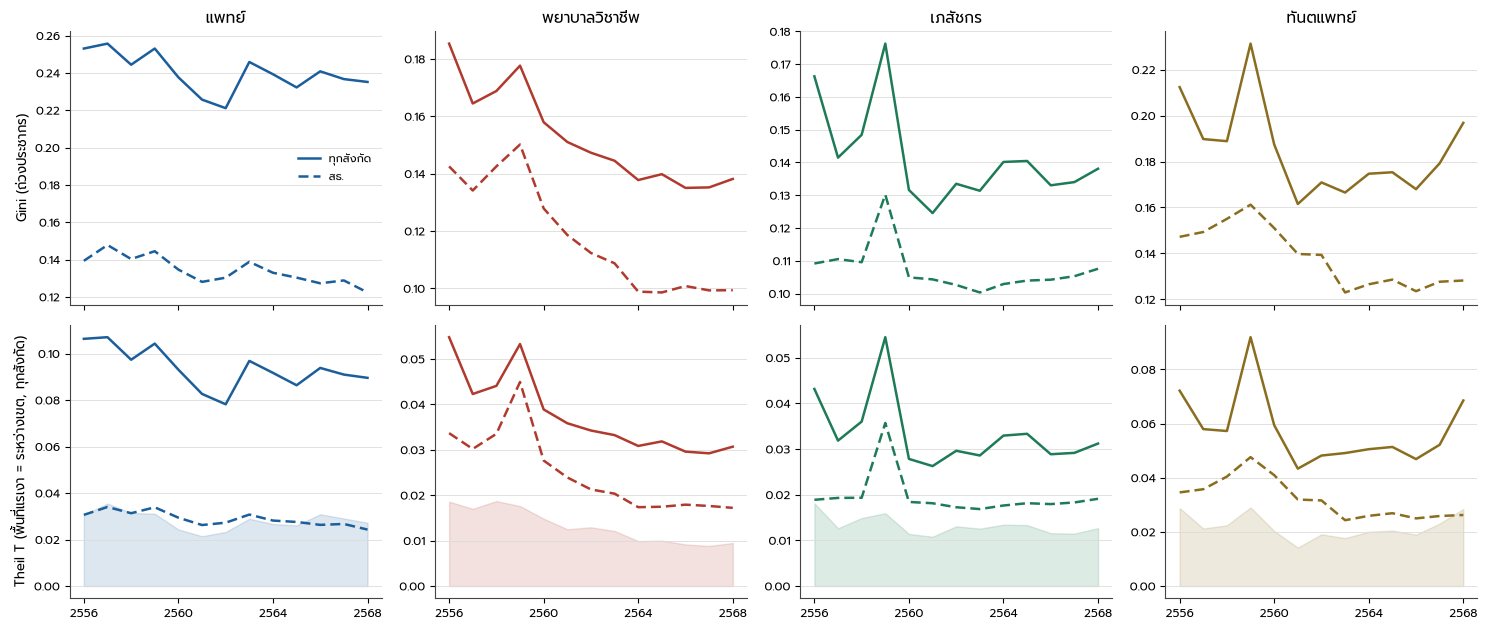

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.4), sharex=True)
for j, c in enumerate(CAD):
    for s, ls in [("all_sectors", "-"), ("moph", (0, (4, 2)))]:
        z = pop_ineq[(pop_ineq.cadre == c) & (pop_ineq.scope == s)]
        axes[0, j].plot(z.year, z.gini_weighted, color=R.CADRE_COLOR[c], ls=ls, lw=1.8, label={"all_sectors": "ทุกสังกัด", "moph": "สธ."}[s])
        axes[1, j].plot(z.year, z.theil_t, color=R.CADRE_COLOR[c], ls=ls, lw=1.8)
        axes[1, j].fill_between(z.year, 0, z.theil_between, color=R.CADRE_COLOR[c], alpha=0.15 if s == "all_sectors" else 0.0)
    axes[0, j].set_title(c)
    for i in (0, 1):
        R.be_ticks(axes[i, j], C.YEARS, 4); axes[i, j].grid(**R.GRID_KW)
axes[0, 0].set_ylabel("Gini (ถ่วงประชากร)"); axes[1, 0].set_ylabel("Theil T (พื้นที่แรเงา = ระหว่างเขต, ทุกสังกัด)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F43_INEQUALITY_TRENDS", fig, pop_ineq, "ความเหลื่อมล้ำของความหนาแน่นกำลังคนต่อประชากรระหว่างจังหวัด 2556–2568 และส่วนที่อยู่ระหว่างเขตสุขภาพ", main=True)
plt.show()

## 2. การเติบโตลดช่องว่างใด
เปรียบเทียบดัชนีภายใต้ตัวหารต่าง ๆ ในหน้าต่างเวลาของตัวหารนั้น พร้อมการแยก Shapley ของการเปลี่ยนแปลง Theil T
ออกเป็นส่วนของ "การกระจายกำลังคน" และ "การกระจายตัวหาร"

ตารางการเพิ่มขึ้นตามกลุ่มความหนาแน่นตั้งต้นใช้เฉพาะบุคลากร สธ. เช่นเดียวกับการทดสอบการตามทันในส่วนที่ 3

In [5]:
# Catching-up analyses (baseline-quartile gains, beta/sigma convergence, scenarios) use MOPH staff only (author decision 27 Sep 2026)
CONV_SCOPES = ["moph"]
win = []
for (c, s, d), g in INEQ.groupby(["cadre", "scope", "denominator"]):
    ys = sorted(g.year)
    for label, a, b in [("own_window", ys[0], ys[-1]), ("common_2023_2025", 2023, 2025)]:
        if a not in ys or b not in ys or a == b:
            continue
        ga, gb = g.set_index("year").loc[a], g.set_index("year").loc[b]
        w0 = WF[(WF.cadre == c) & (WF.scope == s) & (WF.year == a)].set_index("prov_code").W
        w1 = WF[(WF.cadre == c) & (WF.scope == s) & (WF.year == b)].set_index("prov_code").W
        d0 = DEN[(DEN.denominator == d) & (DEN.year == a)].set_index("prov_code").D
        d1 = DEN[(DEN.denominator == d) & (DEN.year == b)].set_index("prov_code").D
        idx = w0.index.intersection(w1.index).intersection(d0.index).intersection(d1.index)
        sh = M.shapley_two_factor(lambda W_, D_: M.theil_t(W_, D_), w0[idx].values, w1[idx].values, d0[idx].values, d1[idx].values)
        win.append(dict(cadre=c, scope=s, denominator=d, window=label, start=a, end=b, provinces=len(idx),
                        gini_start=ga.gini_weighted, gini_end=gb.gini_weighted, gini_change=gb.gini_weighted - ga.gini_weighted,
                        theil_start=ga.theil_t, theil_end=gb.theil_t, theil_change=sh["total"],
                        theil_change_from_workforce=sh["contribution_a"], theil_change_from_denominator=sh["contribution_b"],
                        shapley_residual=sh["residual"], seq_workforce_first=sh["seq_a_first"], seq_denominator_first=sh["seq_b_first"]))
WIN = pd.DataFrame(win)
assert WIN.shapley_residual.abs().max() < 1e-12
S.table("T43_DENOMINATOR_INEQUALITY_CHANGE", WIN, "การเปลี่ยนแปลงความเหลื่อมล้ำภายใต้ตัวหารแต่ละชนิด และการแยก Shapley ของ Theil T", main=True)
display(WIN[(WIN.scope == "moph") & (WIN.window == "own_window")][["cadre", "denominator", "start", "end", "gini_start", "gini_end", "gini_change",
            "theil_change_from_workforce", "theil_change_from_denominator"]].round(4))
for r in WIN.itertuples():
    tag = f"c43_win_{EN[r.cadre]}_{r.scope}_{r.denominator}_{r.window}"
    S.claim(tag + "_gini_start", r.gini_start, "{:.3f}", "")
    S.claim(tag + "_gini_end", r.gini_end, "{:.3f}", "")
    S.claim(tag + "_gini_change", r.gini_change, "{:+.3f}", "")
    S.claim(tag + "_theil_wf", r.theil_change_from_workforce, "{:+.4f}", "")
    S.claim(tag + "_theil_den", r.theil_change_from_denominator, "{:+.4f}", "")

# did initially low-density provinces gain more?  (baseline quartiles, never final growth)
gain = []
for c in CAD:
    for s in CONV_SCOPES:
        w = WF[(WF.cadre == c) & (WF.scope == s)].pivot(index="prov_code", columns="year", values="W")
        p = panel.pivot(index="prov_code", columns="year", values="population")
        dens0 = w[Y0] / p[Y0]
        q = pd.qcut(dens0.rank(method="first"), 4, labels=["Q1 ต่ำสุด", "Q2", "Q3", "Q4 สูงสุด"])
        z = pd.DataFrame({"q": q, "w0": w[Y0], "w1": w[Y1], "p0": p[Y0], "p1": p[Y1]})
        for qq, g in z.groupby("q", observed=True):
            gain.append(dict(cadre=c, scope=s, baseline_quartile=qq, provinces=len(g), pop_share_2025_pct=100 * g.p1.sum() / z.p1.sum(),
                             density_start=1e5 * g.w0.sum() / g.p0.sum(), density_end=1e5 * g.w1.sum() / g.p1.sum(),
                             abs_increase_per100k=1e5 * (g.w1.sum() / g.p1.sum() - g.w0.sum() / g.p0.sum()),
                             pct_increase_density=M.pct_change(g.w0.sum() / g.p0.sum(), g.w1.sum() / g.p1.sum()),
                             share_of_net_staff_increase_pct=100 * (g.w1.sum() - g.w0.sum()) / (z.w1.sum() - z.w0.sum())))
GAIN = pd.DataFrame(gain)
S.table("T43_BASELINE_QUARTILE_GAINS", GAIN, "การเพิ่มขึ้นของความหนาแน่นแยกตามกลุ่มความหนาแน่นตั้งต้น ปี 2556 (ต่อประชากร 100,000)", main=True)
display(GAIN.round(2))
for r in GAIN.itertuples():
    tag = f"c43_q_{EN[r.cadre]}_{r.scope}_{r.baseline_quartile.split()[0]}"
    S.claim(tag + "_pct", r.pct_increase_density, "{:.1f}", "%")
    S.claim(tag + "_abs", r.abs_increase_per100k, "{:.1f}", "ต่อ 100,000")
    S.claim(tag + "_start", r.density_start, "{:.1f}", "ต่อ 100,000")
    S.claim(tag + "_end", r.density_end, "{:.1f}", "ต่อ 100,000")
    S.claim(tag + "_netshare", r.share_of_net_staff_increase_pct, "{:.1f}", "%")
    S.claim(tag + "_popshare", r.pop_share_2025_pct, "{:.1f}", "%")

,cadre,denominator,start,end,gini_start,gini_end,gini_change,theil_change_from_workforce,theil_change_from_denominator
8,ทันตแพทย์,age_scenario_moderate,2013,2025,0.1429,0.1204,-0.0225,-0.0107,0.0010
10,ทันตแพทย์,age_scenario_steep,2013,2025,0.1403,0.1165,-0.0238,-0.0106,0.0005
12,ทันตแพทย์,dental_visits,2022,2025,0.2179,0.1932,-0.0246,0.0061,-0.0259
14,ทันตแพทย์,entitlement,2013,2025,0.1389,0.1194,-0.0196,-0.0105,0.0023
16,ทันตแพทย์,population,2013,2025,0.1472,0.1282,-0.0190,-0.0108,0.0025
26,พยาบาลวิชาชีพ,adjrw,2018,2025,0.1189,0.0983,-0.0206,-0.0075,-0.0022
28,พยาบาลวิชาชีพ,age_scenario_moderate,2013,2025,0.1408,0.0977,-0.0430,-0.0183,0.0019
30,พยาบาลวิชาชีพ,age_scenario_steep,2013,2025,0.1396,0.0981,-0.0416,-0.0179,0.0019
32,พยาบาลวิชาชีพ,entitlement,2013,2025,0.1354,0.0942,-0.0412,-0.0186,0.0037
34,พยาบาลวิชาชีพ,ip_days,2013,2025,0.1359,0.0794,-0.0565,-0.0168,-0.0034


,cadre,scope,baseline_quartile,provinces,pop_share_2025_pct,density_start,density_end,abs_increase_per100k,pct_increase_density,share_of_net_staff_increase_pct
0,แพทย์,moph,Q1 ต่ำสุด,19,28.32,18.48,30.43,11.95,64.66,26.46
1,แพทย์,moph,Q2,19,20.56,23.29,37.04,13.75,59.03,22.00
2,แพทย์,moph,Q3,19,30.03,28.10,40.27,12.17,43.32,29.98
3,แพทย์,moph,Q4 สูงสุด,19,21.09,34.97,47.02,12.05,34.45,21.56
4,พยาบาลวิชาชีพ,moph,Q1 ต่ำสุด,19,33.36,122.17,172.84,50.67,41.47,42.02
5,พยาบาลวิชาชีพ,moph,Q2,19,27.42,151.76,198.65,46.89,30.90,30.45
6,พยาบาลวิชาชีพ,moph,Q3,19,25.55,183.35,222.63,39.27,21.42,25.82
7,พยาบาลวิชาชีพ,moph,Q4 สูงสุด,19,13.67,243.28,246.00,2.72,1.12,1.71
8,เภสัชกร,moph,Q1 ต่ำสุด,19,33.03,9.71,15.52,5.81,59.83,32.56
9,เภสัชกร,moph,Q2,19,31.75,11.64,16.92,5.27,45.29,29.20


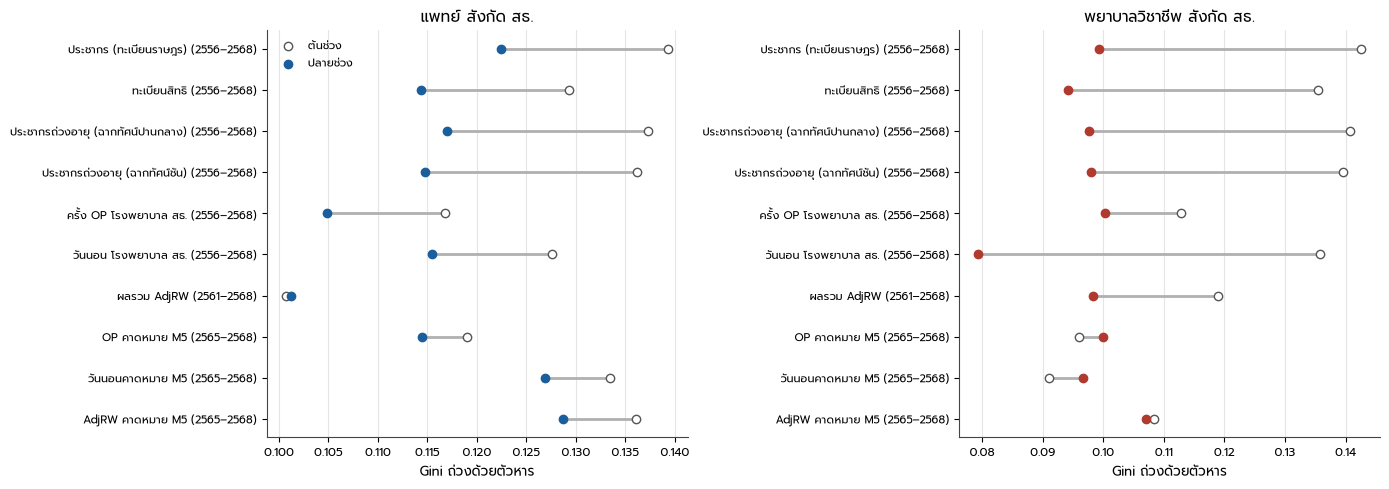

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, ["แพทย์", "พยาบาลวิชาชีพ"]):
    z = WIN[(WIN.cadre == c) & (WIN.scope == "moph") & (WIN.window == "own_window")].set_index("denominator")
    order = [d for d in CADRE_DEN[c] if d in z.index]
    y = np.arange(len(order))
    ax.hlines(y, z.loc[order, "gini_start"], z.loc[order, "gini_end"], color="#b0b0b0", lw=2)
    ax.scatter(z.loc[order, "gini_start"], y, color="white", edgecolor="#555", zorder=3, label="ต้นช่วง")
    ax.scatter(z.loc[order, "gini_end"], y, color=R.CADRE_COLOR[c], zorder=3, label="ปลายช่วง")
    ax.set_yticks(y); ax.set_yticklabels([f"{DEN_TH[d]} ({int(z.loc[d, 'start']) + C.BE}–{int(z.loc[d, 'end']) + C.BE})" for d in order], fontsize=8)
    ax.invert_yaxis(); ax.set_xlabel("Gini ถ่วงด้วยตัวหาร"); ax.set_title(f"{c} สังกัด สธ."); ax.grid(axis="x", color="#e5e5e5")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
S.figure("F43_DENOMINATOR_INEQUALITY", fig, WIN[WIN.scope == "moph"], "ความเหลื่อมล้ำระหว่างจังหวัดของแพทย์และพยาบาล สธ. เมื่อเปลี่ยนตัวหาร (หน้าต่างเวลาของแต่ละตัวหาร)", main=True)
plt.show()

## 3. กำลังตามทันหรือไม่ (sigma/beta convergence) และฉากทัศน์ — บุคลากรสังกัดกระทรวงสาธารณสุขเท่านั้น
การตามทันถามว่าการจัดสรรของกระทรวงสาธารณสุขทำให้จังหวัดที่ตั้งต้นต่ำไล่ตามได้หรือไม่ จึงใช้เฉพาะบุคลากร สธ. (การเติบโตของทุกสังกัดรวมภาคเอกชนซึ่งไม่ได้อยู่ภายใต้กติกาการจัดสรรเดียวกัน)
beta: $\frac{1}{T}\ln(r_{p,t_1}/r_{p,t_0})=a+\beta\ln r_{p,t_0}+e_p$ (β<0 = จังหวัดตั้งต้นต่ำโตเร็วกว่า) ใช้ HC3 SE
ตรวจ regression-to-the-mean ด้วยฐานเฉลี่ยสามปี (2556–2558 → 2566–2568) และช่วงก่อนถ่ายโอน 2556–2565

In [7]:
def beta_conv(c, s, a, b, avg=False, weight=None):
    w = WF[(WF.cadre == c) & (WF.scope == s)].pivot(index="prov_code", columns="year", values="W")
    p = panel.pivot(index="prov_code", columns="year", values="population")
    r = w / p * 1e5
    if avg:
        r0, r1 = r[[a, a + 1, a + 2]].mean(axis=1), r[[b - 2, b - 1, b]].mean(axis=1)
        T = (b - 1) - (a + 1)
    else:
        r0, r1, T = r[a], r[b], b - a
    ok = (r0 > 0) & (r1 > 0)
    y = np.log(r1[ok] / r0[ok]) / T
    X = sm.add_constant(np.log(r0[ok]))
    X = pd.concat([X, pd.get_dummies(KEY.loc[ok[ok].index, "health_region"], prefix="reg", drop_first=True, dtype=float)], axis=1) if weight == "region_fe" else X
    wts = p.loc[ok[ok].index, a] if weight == "pop" else None
    m = (sm.WLS(y, X, weights=wts) if wts is not None else sm.OLS(y, X)).fit(cov_type="HC3")
    bcol = X.columns[1]
    lo, hi = m.conf_int().loc[bcol]
    return dict(cadre=c, scope=s, start=a, end=b, baseline="3-year average" if avg else "single year",
                variant=weight or "unweighted", beta=m.params[bcol], lo95=lo, hi95=hi, n=int(ok.sum()),
                sigma_start=np.std(np.log(r0[ok])), sigma_end=np.std(np.log(r1[ok])), dropped_zero=int((~ok).sum()))

bc = []
for c in CAD:
    for s in CONV_SCOPES:
        bc.append(beta_conv(c, s, Y0, Y1))
        bc.append(beta_conv(c, s, Y0, Y1, avg=True))
        bc.append(beta_conv(c, s, Y0, C.CFG["years"]["pre_transfer_last"]))
        bc.append(beta_conv(c, s, 2018, Y1))
        bc.append(beta_conv(c, s, Y0, Y1, weight="pop"))
        bc.append(beta_conv(c, s, Y0, Y1, weight="region_fe"))
BC = pd.DataFrame(bc)
BC["beta_direction"] = np.where(BC.hi95 < 0, "converging", np.where(BC.lo95 > 0, "diverging", "inconclusive"))
BC["sigma_change"] = BC.sigma_end - BC.sigma_start
S.table("T43_CONVERGENCE", BC, "beta- และ sigma-convergence ของความหนาแน่นต่อประชากร (log) ตามช่วงเวลาและการกำหนดฐาน", main=True)
display(BC.round(4))
for r in BC.itertuples():
    tag = f"c43_beta_{EN[r.cadre]}_{r.scope}_{r.start}_{r.end}_{'avg' if r.baseline.startswith('3') else 'single'}_{r.variant}"
    S.claim(tag, r.beta, "{:.4f}", "", "T43_CONVERGENCE")
    S.claim(tag + "_lo", r.lo95, "{:.4f}", "")
    S.claim(tag + "_hi", r.hi95, "{:.4f}", "")
    S.text_claim(tag + "_dir", r.beta_direction)
    S.claim(tag + "_sigma_start", r.sigma_start, "{:.3f}", "")
    S.claim(tag + "_sigma_end", r.sigma_end, "{:.3f}", "")

,cadre,scope,start,end,baseline,variant,beta,lo95,hi95,n,sigma_start,sigma_end,dropped_zero,beta_direction,sigma_change
0,แพทย์,moph,2013,2025,single year,unweighted,-0.0200,-0.0322,-0.0077,76,0.2566,0.2423,0,converging,-0.0143
1,แพทย์,moph,2013,2025,3-year average,unweighted,-0.0180,-0.0290,-0.0069,76,0.2588,0.2421,0,converging,-0.0167
2,แพทย์,moph,2013,2022,single year,unweighted,-0.0184,-0.0320,-0.0048,76,0.2566,0.2485,0,converging,-0.0081
3,แพทย์,moph,2018,2025,single year,unweighted,-0.0147,-0.0324,0.0030,76,0.2366,0.2423,0,inconclusive,0.0057
4,แพทย์,moph,2013,2025,single year,pop,-0.0224,-0.0345,-0.0103,76,0.2566,0.2423,0,converging,-0.0143
5,แพทย์,moph,2013,2025,single year,region_fe,-0.0183,-0.0309,-0.0056,76,0.2566,0.2423,0,converging,-0.0143
6,พยาบาลวิชาชีพ,moph,2013,2025,single year,unweighted,-0.0366,-0.0475,-0.0257,76,0.2876,0.2017,0,converging,-0.0859
7,พยาบาลวิชาชีพ,moph,2013,2025,3-year average,unweighted,-0.0334,-0.0435,-0.0233,76,0.2711,0.2032,0,converging,-0.0678
8,พยาบาลวิชาชีพ,moph,2013,2022,single year,unweighted,-0.0438,-0.0569,-0.0306,76,0.2876,0.2022,0,converging,-0.0854
9,พยาบาลวิชาชีพ,moph,2018,2025,single year,unweighted,-0.0329,-0.0471,-0.0186,76,0.2345,0.2017,0,converging,-0.0329


### ฉากทัศน์ 20 ปี (ไม่ใช่แผนจัดสรรจริง)
เกณฑ์ "ใกล้เท่าเทียม" ที่กำหนดล่วงหน้าเพื่อประกอบภาพ (ไม่ใช่ค่าที่เหมาะสมที่สุดทางวิทยาศาสตร์): Gini ≤ 0.10 **และ** P90/P10 ≤ 1.5
ตัวหาร: ประชากรปี 2568 คงสัดส่วนเดิม (ไม่มี projection ประชากรรายจังหวัดทางการ) การเติบโตรวมใช้ CAGR 2556–2568 ของบุคลากร สธ. ใน 76 จังหวัดของวิชาชีพนั้น
1) โตอย่างเดียว (ส่วนแบ่งคงเดิม) 2) เกลี่ยอย่างเดียว $q_{t+1}=(1-\lambda)q_t+\lambda d$ λ = 0.10 3) โต + เกลี่ย
4) โต + จัดสรรเฉพาะส่วนเพิ่ม (ไม่ลดคนในจังหวัดใด): ส่วนเพิ่มแต่ละปีแบ่งตามช่องว่างบวกกับเป้าสัดส่วนประชากร

In [8]:
H = IQ["horizon_years"]
LAM = IQ["lambda_share"]
def scen_stats(W, D):
    r = W / D
    return dict(gini=M.weighted_gini(r, D), p90p10=M.weighted_quantile(r, D, .9) / M.weighted_quantile(r, D, .1),
                band=float(D[np.abs(r / (W.sum() / D.sum()) - 1) <= IQ["near_band"]].sum() / D.sum()), pooled_per100k=1e5 * W.sum() / D.sum())

sc_rows, sc_prov = [], []
for c in CAD:
    for s in CONV_SCOPES:
        w = WF[(WF.cadre == c) & (WF.scope == s)].pivot(index="prov_code", columns="year", values="W")
        D = panel[panel.year == Y1].set_index("prov_code").population.reindex(w.index).to_numpy(float)
        W0 = w[Y1].to_numpy(float)
        g = M.cagr(w[Y0].sum(), w[Y1].sum(), Y1 - Y0)
        d = D / D.sum()
        for name in ["growth_only", "redistribution_only", "growth_plus_redistribution", "growth_additions_only"]:
            W_ = W0.copy()
            for t in range(0, H + 1):
                st = scen_stats(W_, D)
                sc_rows.append(dict(cadre=c, scope=s, scenario=name, year=Y1 + t, total=W_.sum(), **st,
                                    near_equality=(st["gini"] <= IQ["gini_threshold"]) and (st["p90p10"] <= IQ["p90p10_threshold"]),
                                    min_province_change_vs_2025=float((W_ - W0).min())))
                if t == H:
                    sc_prov.append(pd.DataFrame({"cadre": c, "scope": s, "scenario": name, "prov_code": w.index, "W_2025": W0, "W_final": W_,
                                                 "density_final_per100k": 1e5 * W_ / D}))
                tot_next = W_.sum() * (1 + g) if name != "redistribution_only" else W_.sum()
                q = W_ / W_.sum()
                if name == "growth_only":
                    W_ = tot_next * q
                elif name in ("redistribution_only", "growth_plus_redistribution"):
                    W_ = tot_next * ((1 - LAM) * q + LAM * d)
                else:  # additions only: increment split by positive gaps to the population-share target
                    inc = tot_next - W_.sum()
                    gap = np.clip(tot_next * d - W_, 0, None)
                    W_ = W_ + (inc * gap / gap.sum() if gap.sum() > 0 else inc * d)
SC = pd.DataFrame(sc_rows)
SCP = pd.concat(sc_prov, ignore_index=True)
# validation: uniform proportional growth with fixed denominator shares leaves relative inequality unchanged
chk = SC[SC.scenario == "growth_only"].groupby(["cadre", "scope"]).gini.agg(lambda s: s.max() - s.min())
assert chk.abs().max() < 1e-12, "growth-only scenario changed relative inequality"
S.table("T43_SCENARIOS", SC, "ฉากทัศน์ 20 ปี: ความหนาแน่นรวม ความเหลื่อมล้ำ และการเข้าใกล้เกณฑ์ใกล้เท่าเทียม (เงื่อนไข ไม่ใช่การพยากรณ์)", main=True)
S.table("T43_SCENARIO_PROVINCES", SCP, "จำนวนและความหนาแน่นรายจังหวัดปีสุดท้ายของแต่ละฉากทัศน์")
summ = []
for (c, s, n), g in SC.groupby(["cadre", "scope", "scenario"]):
    reach = g[g.near_equality]
    summ.append(dict(cadre=c, scope=s, scenario=n, gini_2025=g.gini.iloc[0], gini_final=g.gini.iloc[-1], p90p10_final=g.p90p10.iloc[-1],
                     pooled_final_per100k=g.pooled_per100k.iloc[-1], reaches_criterion=len(reach) > 0,
                     first_year_be=(reach.year.min() + C.BE) if len(reach) else np.nan,
                     provinces_losing_staff=int((SCP[(SCP.cadre == c) & (SCP.scope == s) & (SCP.scenario == n)].W_final < SCP[(SCP.cadre == c) & (SCP.scope == s) & (SCP.scenario == n)].W_2025 - 1e-9).sum())))
SCS = pd.DataFrame(summ)
S.table("T43_SCENARIO_SUMMARY", SCS, "สรุปฉากทัศน์: ถึงเกณฑ์ใกล้เท่าเทียมหรือไม่ และจำนวนจังหวัดที่ต้องลดคน", main=True)
display(SCS.round(3))
for r in SCS.itertuples():
    tag = f"c43_scn_{EN[r.cadre]}_{r.scope}_{r.scenario}"
    S.claim(tag + "_gini_final", r.gini_final, "{:.3f}", "")
    S.claim(tag + "_gini_2025", r.gini_2025, "{:.3f}", "")
    S.claim(tag + "_pooled_final", r.pooled_final_per100k, "{:.1f}", "ต่อ 100,000")
    S.claim(tag + "_first_year", r.first_year_be if r.reaches_criterion else -1, "{:.0f}", "พ.ศ.")
    S.claim(tag + "_losing", r.provinces_losing_staff, "int", "จังหวัด")
    S.text_claim(tag + "_reaches", "ถึง" if r.reaches_criterion else "ไม่ถึงภายใน 20 ปี")

,cadre,scope,scenario,gini_2025,gini_final,p90p10_final,pooled_final_per100k,reaches_criterion,first_year_be,provinces_losing_staff
0,ทันตแพทย์,moph,growth_additions_only,0.128,0.000,1.000,16.966,True,2571.0,0
1,ทันตแพทย์,moph,growth_only,0.128,0.128,1.879,16.966,False,NaN,0
2,ทันตแพทย์,moph,growth_plus_redistribution,0.128,0.016,1.077,16.966,True,2573.0,0
3,ทันตแพทย์,moph,redistribution_only,0.128,0.016,1.077,10.372,True,2573.0,49
4,พยาบาลวิชาชีพ,moph,growth_additions_only,0.099,0.000,1.000,302.251,True,2569.0,0
5,พยาบาลวิชาชีพ,moph,growth_only,0.099,0.099,1.540,302.251,False,NaN,0
6,พยาบาลวิชาชีพ,moph,growth_plus_redistribution,0.099,0.012,1.054,302.251,True,2569.0,1
7,พยาบาลวิชาชีพ,moph,redistribution_only,0.099,0.012,1.054,202.634,True,2569.0,43
8,เภสัชกร,moph,growth_additions_only,0.108,0.000,1.000,35.747,True,2569.0,0
9,เภสัชกร,moph,growth_only,0.108,0.108,1.662,35.747,False,NaN,0


/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_53180/2201073270.py:17: UserWarning: Glyph 946 (\N{GREEK SMALL LETTER BETA}) missing from font(s) Prompt.
  fig.tight_layout()
/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_53180/2201073270.py:17: UserWarning: Glyph 9675 (\N{WHITE CIRCLE}) missing from font(s) Prompt.
  fig.tight_layout()
/var/folders/y7/8_qm7_795fnd2fb2ztv5_j_w0000gn/T/ipykernel_53180/2201073270.py:17: UserWarning: Glyph 9633 (\N{WHITE SQUARE}) missing from font(s) Prompt.
  fig.tight_layout()
/Users/rama-hpsr/Desktop/HPSR_QUANTI/HRH/src/chapter4/reporting.py:110: UserWarning: Glyph 9675 (\N{WHITE CIRCLE}) missing from font(s) Prompt.
  fig.savefig(f"{stem}.{ext}", dpi=C.CFG["figures"]["dpi"])
/Users/rama-hpsr/Desktop/HPSR_QUANTI/HRH/src/chapter4/reporting.py:110: UserWarning: Glyph 9633 (\N{WHITE SQUARE}) missing from font(s) Prompt.
  fig.savefig(f"{stem}.{ext}", dpi=C.CFG["figures"]["dpi"])
/Users/rama-hpsr/Desktop/HPSR_QUANTI/HRH/src/chapter4/

/Users/rama-hpsr/Desktop/HPSR_QUANTI/HRH/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9675 (\N{WHITE CIRCLE}) missing from font(s) Prompt.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/rama-hpsr/Desktop/HPSR_QUANTI/HRH/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9633 (\N{WHITE SQUARE}) missing from font(s) Prompt.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/rama-hpsr/Desktop/HPSR_QUANTI/HRH/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 946 (\N{GREEK SMALL LETTER BETA}) missing from font(s) Prompt.
  fig.canvas.print_figure(bytes_io, **kw)


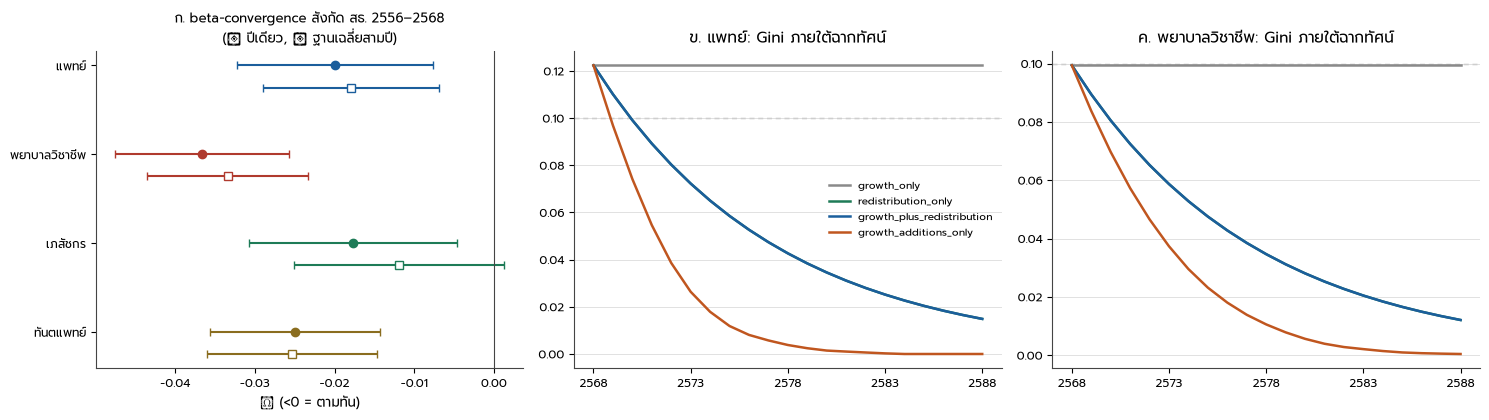

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
for c in CAD:
    b = BC[(BC.cadre == c) & (BC.scope == "moph") & (BC.start == Y0) & (BC.end == Y1) & (BC.baseline == "single year") & (BC.variant == "unweighted")].iloc[0]
    ax.errorbar(b.beta, CAD.index(c), xerr=[[b.beta - b.lo95], [b.hi95 - b.beta]], fmt="o", color=R.CADRE_COLOR[c], capsize=3)
    b2 = BC[(BC.cadre == c) & (BC.scope == "moph") & (BC.baseline != "single year")].iloc[0]
    ax.errorbar(b2.beta, CAD.index(c) + 0.25, xerr=[[b2.beta - b2.lo95], [b2.hi95 - b2.beta]], fmt="s", mfc="white", color=R.CADRE_COLOR[c], capsize=3)
ax.axvline(0, color="#444", lw=0.8); ax.set_yticks(range(4)); ax.set_yticklabels(CAD); ax.invert_yaxis()
ax.set_xlabel("β (<0 = ตามทัน)"); ax.set_title("ก. beta-convergence สังกัด สธ. 2556–2568\n(○ ปีเดียว, □ ฐานเฉลี่ยสามปี)", fontsize=9.5)
for ax, c in zip(axes[1:], ["แพทย์", "พยาบาลวิชาชีพ"]):
    for n, col in [("growth_only", "#8a8a8a"), ("redistribution_only", "#1e7b57"), ("growth_plus_redistribution", "#1b5e9c"), ("growth_additions_only", "#c0561f")]:
        z = SC[(SC.cadre == c) & (SC.scope == "moph") & (SC.scenario == n)]
        ax.plot(z.year, z.gini, color=col, lw=1.8, label=n)
    ax.axhline(IQ["gini_threshold"], **R.REFLINE_KW)
    ax.set_title(f"{'ข' if c == 'แพทย์' else 'ค'}. {c}: Gini ภายใต้ฉากทัศน์"); R.be_ticks(ax, list(range(Y1, Y1 + H + 1)), 5); ax.grid(**R.GRID_KW)
axes[1].legend(frameon=False, fontsize=7.5)
fig.tight_layout()
S.figure("F43_CONVERGENCE_SCENARIOS", fig, pd.concat([BC.assign(panel="A"), SC[SC.scope == "moph"].assign(panel="BC")]),
         "การตามทันของจังหวัดที่ตั้งต้นต่ำ และความเหลื่อมล้ำภายใต้ฉากทัศน์ 20 ปี", main=True)
plt.show()

## 4. จังหวัดที่ควรให้ความสำคัญเปลี่ยนไปหรือไม่เมื่อเปลี่ยนตัวหาร
$R_p=(W_p/D_p)/(\sum W/\sum D)$ ปี 2568, กลุ่มต่ำสุดหนึ่งในสี่ = 19 จังหวัด เรียงตาม R แล้วตามรหัสจังหวัดเมื่อเท่ากัน
"ช่องว่างตามกฎสัดส่วน" $=\sum W\,D_p/\sum D-W_p$ ไม่ใช่จำนวนขาดแคลนหรือส่วนเกินที่พิสูจน์แล้ว
น้ำหนักอายุที่ประมาณไม่ผ่านเกณฑ์ (4.2.3) จึงใช้ **ฉากทัศน์ปานกลาง** แทนในชุดหกตัวหาร และระบุเป็นสมมติฐาน

In [10]:
SIX = ["population", "entitlement", "age_scenario_moderate", "op_visits", "ip_days", "adjrw"]
EXT = SIX + ["m5_op_moph", "m5_ip_moph", "m5_adjrw"]
Q = IQ["priority_quartile"]
pri = []
for c, s in [("แพทย์", "moph"), ("แพทย์", "all_sectors"), ("พยาบาลวิชาชีพ", "moph"), ("ทันตแพทย์", "moph"), ("เภสัชกร", "moph")]:
    dens = CADRE_DEN[c] if s == "moph" else POP_DEN
    for d in dens:
        z = WF[(WF.cadre == c) & (WF.scope == s)].merge(DEN[DEN.denominator == d], on=["year", "prov_code"])
        yy = Y1 if Y1 in z.year.values else z.year.max()
        z = z[z.year == yy].copy()
        z["R"] = (z.W / z.D) / (z.W.sum() / z.D.sum())
        z = z.sort_values(["R", "prov_code"]).reset_index(drop=True)
        z["rank"] = np.arange(1, len(z) + 1)
        z["priority"] = z["rank"] <= Q
        z["proportional_gap"] = z.W.sum() * z.D / z.D.sum() - z.W
        cut = z.R.iloc[Q - 1]
        z["near_cutoff"] = (z.R / cut - 1).abs() <= 0.02
        z["cadre"], z["scope"], z["denominator"], z["year_used"] = c, s, d, yy
        pri.append(z)
PRI = pd.concat(pri, ignore_index=True)
PRI["province"] = PRI.prov_code.map(NAME)
S.table("T43_PRIORITY_RANKS", PRI[["cadre", "scope", "denominator", "year_used", "prov_code", "province", "W", "D", "R", "rank", "priority", "near_cutoff", "proportional_gap"]],
        "อันดับจังหวัด อัตราส่วนเทียบค่ารวม R และช่องว่างตามกฎสัดส่วน ปี 2568 (หรือปีล่าสุดของตัวหาร)", main=True)
mp = PRI[(PRI.cadre == "แพทย์") & (PRI.scope == "moph")]
memb = mp.pivot(index="province", columns="denominator", values="priority")
in_all6 = sorted(memb.index[memb[SIX].all(axis=1)])
in_any6 = sorted(memb.index[memb[SIX].any(axis=1)])
in_all_ext = sorted(memb.index[memb[EXT].all(axis=1)])
S.text_claim("c43_pri_all6", ", ".join(in_all6))
S.claim("c43_pri_all6_n", len(in_all6), "int", "จังหวัด")
S.claim("c43_pri_any6_n", len(in_any6), "int", "จังหวัด")
S.text_claim("c43_pri_all9", ", ".join(in_all_ext))
S.claim("c43_pri_all9_n", len(in_all_ext), "int", "จังหวัด")
# overlaps between lists
ov = []
for a in EXT:
    for b in EXT:
        if a >= b:
            continue
        la, lb = set(memb.index[memb[a]]), set(memb.index[memb[b]])
        ra = mp[mp.denominator == a].set_index("province")["rank"]
        rb = mp[mp.denominator == b].set_index("province")["rank"]
        ov.append(dict(denominator_a=a, denominator_b=b, intersection=len(la & lb), jaccard=M.jaccard(la, lb),
                       spearman=spearmanr(ra, rb.reindex(ra.index)).statistic))
OV = pd.DataFrame(ov)
S.table("T43_PRIORITY_OVERLAP", OV, "ความทับซ้อนของรายชื่อ 19 จังหวัดระหว่างตัวหาร (แพทย์ สธ. ปี 2568)", main=True)
display(OV.round(3))
S.claim("c43_pri_min_intersection", OV.intersection.min(), "int", "จังหวัด")
S.claim("c43_pri_max_intersection", OV.intersection.max(), "int", "จังหวัด")
S.claim("c43_pri_pop_op_intersection", OV[(OV.denominator_a == "op_visits") & (OV.denominator_b == "population")].intersection.iloc[0], "int", "จังหวัด")
S.claim("c43_pri_pop_m5op_intersection", OV[(OV.denominator_a == "m5_op_moph") & (OV.denominator_b == "population")].intersection.iloc[0], "int", "จังหวัด")
S.claim("c43_pri_pop_adjrw_intersection", OV[(OV.denominator_a == "adjrw") & (OV.denominator_b == "population")].intersection.iloc[0], "int", "จังหวัด")

# uncertainty of M5 priority membership from the 4.2 bootstrap draws
up = []
for o in ["op_moph", "ip_moph", "adjrw"]:
    b = M5B[M5B.outcome == o]
    w = WF[(WF.cadre == "แพทย์") & (WF.scope == "moph") & (WF.year == Y1)].set_index("prov_code").W
    cnt = pd.Series(0.0, index=w.index)
    draws = b.draw.unique()
    for dr in draws:
        e = b[b.draw == dr].set_index("prov_code").E_equiv_pop.reindex(w.index)
        r = (w / e) / (w.sum() / e.sum())
        low = r.sort_values(kind="mergesort").index[:Q]
        cnt[low] += 1
    up.append(pd.DataFrame({"outcome": o, "prov_code": cnt.index, "prob_priority": cnt.values / len(draws), "draws": len(draws)}))
UP = pd.concat(up, ignore_index=True)
UP["province"] = UP.prov_code.map(NAME)
S.table("T43_M5_PRIORITY_PROBABILITY", UP, "ความน่าจะเป็นที่จังหวัดอยู่ในกลุ่ม 19 จังหวัดต่ำสุดภายใต้ตัวหาร M5 (bootstrap 4.2)", main=True)
unc = UP[(UP.prob_priority > 0.1) & (UP.prob_priority < 0.9)]
S.claim("c43_m5_uncertain_n", unc.province.nunique(), "int", "จังหวัด")
for o in ["op_moph", "ip_moph", "adjrw"]:
    S.claim(f"c43_m5_uncertain_{o}", len(unc[unc.outcome == o]), "int", "จังหวัด")

# province examples: Bueng Kan and the provinces whose classification changes most
BUENG = "บึงกาฬ"
bk_row = mp[mp.province == BUENG].set_index("denominator")[["rank", "R", "priority"]]
S.table("T43_BUENGKAN", bk_row.reset_index(), "บึงกาฬ: อันดับและสถานะภายใต้ทุกตัวหาร (แพทย์ สธ.)")
S.text_claim("c43_buengkan_all", "ใช่" if bk_row.loc[EXT, "priority"].all() else "ไม่ใช่")
S.claim("c43_buengkan_worst_rank", bk_row["rank"].max(), "int", "")
rk = mp.pivot(index="province", columns="denominator", values="rank")
swing = (rk[EXT].max(axis=1) - rk[EXT].min(axis=1)).sort_values(ascending=False)
switchers = [p for p in swing.index if memb.loc[p, EXT].any() and not memb.loc[p, EXT].all()][:6]
SW = rk.loc[switchers, EXT].reset_index()
S.table("T43_PRIORITY_SWITCHERS", SW, "จังหวัดที่อันดับเปลี่ยนมากที่สุดเมื่อเปลี่ยนตัวหาร (แพทย์ สธ. ปี 2568)")
S.text_claim("c43_switchers", ", ".join(switchers))
for p_ in ["อำนาจเจริญ", "กำแพงเพชร", "เลย", "ชัยภูมิ"]:
    S.text_claim(f"c43_hyp_{p_}", "อยู่ในกลุ่มทุกตัวหารหกชุด" if p_ in in_all6 else "ไม่ได้อยู่ในกลุ่มทุกตัวหารหกชุด")
for p_ in switchers[:4] + [BUENG]:
    for d in EXT:
        S.claim(f"c43_rank_{p_}_{d}", rk.loc[p_, d], "int", "อันดับ")

,denominator_a,denominator_b,intersection,jaccard,spearman
0,entitlement,population,16,0.727,0.958
1,entitlement,op_visits,8,0.267,0.358
2,entitlement,ip_days,12,0.462,0.727
3,entitlement,m5_op_moph,13,0.520,0.868
4,entitlement,m5_ip_moph,16,0.727,0.943
5,entitlement,m5_adjrw,14,0.583,0.883
6,age_scenario_moderate,population,18,0.900,0.987
7,age_scenario_moderate,entitlement,16,0.727,0.936
8,age_scenario_moderate,op_visits,7,0.226,0.406
9,age_scenario_moderate,ip_days,12,0.462,0.698


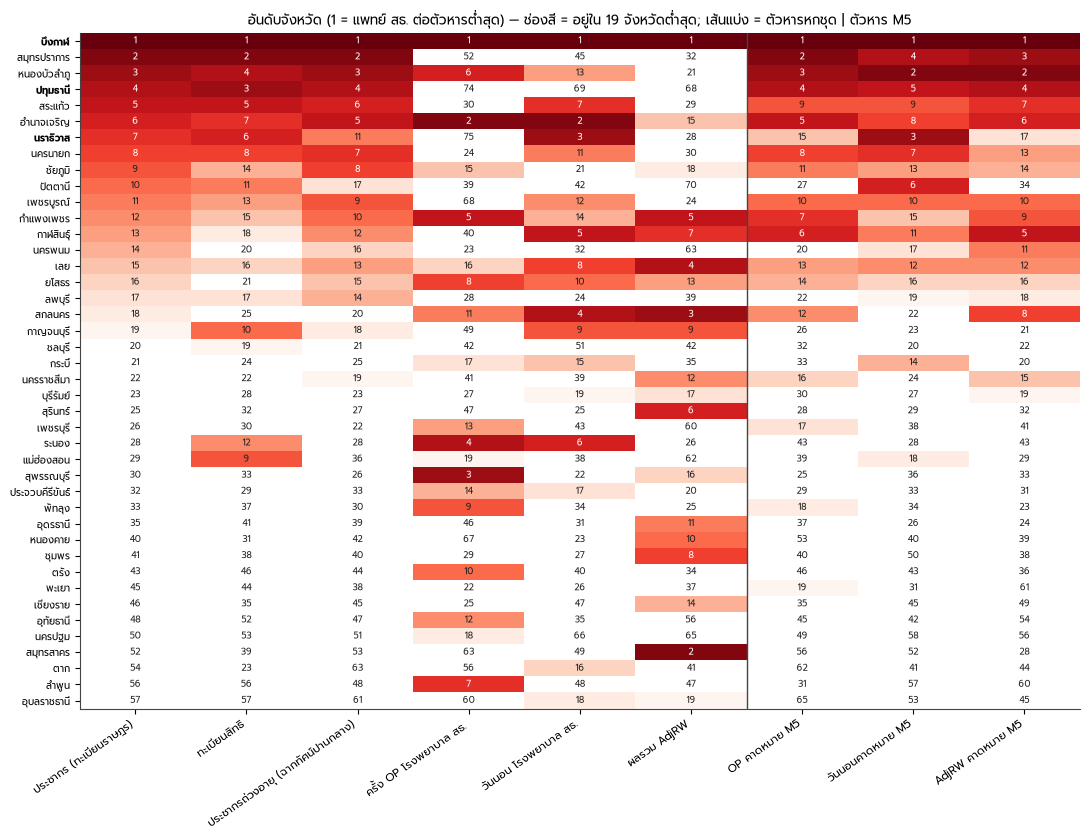

In [11]:
fig, ax = plt.subplots(figsize=(11, 8.5))
show_p = sorted(set(in_any6) | set(memb.index[memb[EXT].any(axis=1)]), key=lambda p: rk.loc[p, "population"])
mat = rk.loc[show_p, EXT].to_numpy(float)
im = ax.imshow(np.where(mat <= Q, mat, np.nan), cmap="Reds_r", aspect="auto", vmin=1, vmax=Q)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{int(mat[i, j])}", ha="center", va="center", fontsize=6.5, color="#222" if mat[i, j] > 8 or mat[i, j] > Q else "white")
ax.set_xticks(range(len(EXT))); ax.set_xticklabels([DEN_TH[d] for d in EXT], rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(show_p))); ax.set_yticklabels(show_p, fontsize=7)
for tl in ax.get_yticklabels():
    if tl.get_text() in (BUENG, "ปทุมธานี", "นราธิวาส"):
        tl.set_fontweight("bold")
ax.axvline(5.5, color="#444", lw=1)
ax.set_title("อันดับจังหวัด (1 = แพทย์ สธ. ต่อตัวหารต่ำสุด) — ช่องสี = อยู่ใน 19 จังหวัดต่ำสุด; เส้นแบ่ง = ตัวหารหกชุด | ตัวหาร M5", fontsize=9.5)
fig.tight_layout()
S.figure("F43_PRIORITY_SWITCHES", fig, mp, "การเปลี่ยนกลุ่มจังหวัดที่ควรให้ความสำคัญเมื่อเปลี่ยนตัวหาร (แพทย์ สธ. ปี 2568; ขอบเขตบุคลากรเดียวกัน)", main=True)
plt.show()

### ตรวจคำถามของผู้เขียน: ปทุมธานีและนราธิวาส
แกน x = ประชากรต่อแพทย์ สธ. แกน y = ครั้ง OP (โรงพยาบาล สธ.) ต่อแพทย์ สธ. — ใช้ตัวหารแพทย์ชุดเดียวกันทั้งสองแกน
อัตลักษณ์ $y/x=\text{OP}/\text{ประชากร}$ เส้นทแยงคือระดับบริการต่อประชากรคงที่ ตัวหารร่วมทำให้สองแกนสัมพันธ์กันเองได้
จึงไม่ใช่หลักฐานของผลเชิงเหตุผลของจำนวนแพทย์

,province,population,op_visits,ip_days,physicians,nurses,pop_per_physician,op_per_physician,op_per_person,pop_per_nurse,ipdays_per_nurse
prov_code,,,,,,,,,,,
13,ปทุมธานี,1229364,1239239.0,309968.0,279.0,1479.0,4406.32,4441.72,1.01,831.21,209.58
96,นราธิวาส,823277,981556.0,474113.0,231.0,1633.0,3563.97,4249.16,1.19,504.15,290.33


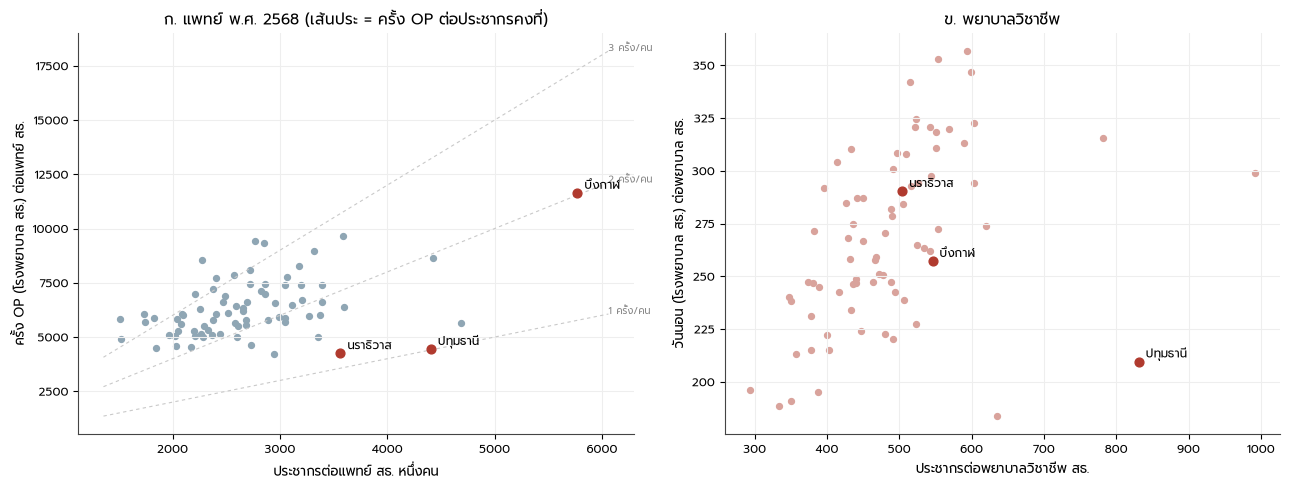

In [12]:
pv = panel[panel.year == Y1].set_index("prov_code")
wv = WF[(WF.scope == "moph") & (WF.year == Y1)].pivot(index="prov_code", columns="cadre", values="W")
V = pd.DataFrame({"province": pv.province, "population": pv.population, "op_visits": pv.moph_op_visits, "ip_days": pv.moph_ip_days,
                  "physicians": wv["แพทย์"], "nurses": wv["พยาบาลวิชาชีพ"]})
V["pop_per_physician"] = V.population / V.physicians
V["op_per_physician"] = V.op_visits / V.physicians
V["op_per_person"] = V.op_visits / V.population
V["pop_per_nurse"] = V.population / V.nurses
V["ipdays_per_nurse"] = V.ip_days / V.nurses
assert np.allclose(V.op_per_physician / V.pop_per_physician, V.op_per_person)
S.table("T43_PROVINCE_VERIFICATION", V.reset_index(), f"ข้อมูลตรวจสอบรายจังหวัด พ.ศ. {C.be(Y1)}: บุคลากร สธ. ประชากร ครั้ง OP และอัตราส่วน", main=True)
chk_p = V[V.province.isin(["ปทุมธานี", "นราธิวาส"])]
display(chk_p.round(2))
for _, r in chk_p.iterrows():
    for col in ["population", "op_visits", "physicians", "nurses", "pop_per_physician", "op_per_physician", "op_per_person"]:
        S.claim(f"c43_verify_{r.province}_{col}", r[col], "{:,.2f}" if "per" in col else "int", "")
S.claim("c43_verify_median_op_per_person", V.op_per_person.median(), "{:.2f}", "ครั้ง/คน")
S.claim("c43_verify_rank_op_per_person_pathum", int(V.op_per_person.rank().loc[V.province == "ปทุมธานี"].iloc[0]), "int", "อันดับจากต่ำสุด")
S.claim("c43_verify_rank_op_per_person_narathiwat", int(V.op_per_person.rank().loc[V.province == "นราธิวาส"].iloc[0]), "int", "อันดับจากต่ำสุด")
S.claim("c43_verify_rank_pop_per_phys_pathum", int(V.pop_per_physician.rank(ascending=False).loc[V.province == "ปทุมธานี"].iloc[0]), "int", "อันดับจากสูงสุด")
S.claim("c43_verify_rank_pop_per_phys_narathiwat", int(V.pop_per_physician.rank(ascending=False).loc[V.province == "นราธิวาส"].iloc[0]), "int", "อันดับจากสูงสุด")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(V.pop_per_physician, V.op_per_physician, s=18, color="#8fa6b4")
xs = np.linspace(V.pop_per_physician.min() * 0.9, V.pop_per_physician.max() * 1.05, 50)
for k in [1.0, 2.0, 3.0]:
    ax.plot(xs, k * xs, color="#c9c9c9", lw=0.8, ls=(0, (3, 3)))
    ax.annotate(f"{k:.0f} ครั้ง/คน", (xs[-1], k * xs[-1]), fontsize=7, color="#888")
for _, r in V.iterrows():
    if r.province in ("ปทุมธานี", "นราธิวาส", BUENG):
        ax.scatter(r.pop_per_physician, r.op_per_physician, s=40, color="#b03a2e", zorder=3)
        ax.annotate(r.province, (r.pop_per_physician, r.op_per_physician), xytext=(5, 3), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("ประชากรต่อแพทย์ สธ. หนึ่งคน"); ax.set_ylabel("ครั้ง OP (โรงพยาบาล สธ.) ต่อแพทย์ สธ.")
ax.set_title(f"ก. แพทย์ พ.ศ. {C.be(Y1)} (เส้นประ = ครั้ง OP ต่อประชากรคงที่)"); ax.grid(color="#eee")
ax = axes[1]
ax.scatter(V.pop_per_nurse, V.ipdays_per_nurse, s=18, color="#d9a39c")
for _, r in V.iterrows():
    if r.province in ("ปทุมธานี", "นราธิวาส", BUENG):
        ax.scatter(r.pop_per_nurse, r.ipdays_per_nurse, s=40, color="#b03a2e", zorder=3)
        ax.annotate(r.province, (r.pop_per_nurse, r.ipdays_per_nurse), xytext=(5, 3), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("ประชากรต่อพยาบาลวิชาชีพ สธ."); ax.set_ylabel("วันนอน (โรงพยาบาล สธ.) ต่อพยาบาล สธ."); ax.set_title("ข. พยาบาลวิชาชีพ"); ax.grid(color="#eee")
fig.tight_layout()
S.figure("F43_PROVINCE_VERIFICATION", fig, V.reset_index(), f"ประชากรต่อบุคลากรและบริการต่อบุคลากร รายจังหวัด พ.ศ. {C.be(Y1)} (ปทุมธานี นราธิวาส บึงกาฬ)", main=True)
plt.show()

In [13]:
manifest = S.finalize()
print({k: manifest[k] for k in ["n_tables", "n_figures", "n_claims", "seconds"]})

{'n_tables': 15, 'n_figures': 5, 'n_claims': 999, 'seconds': 8.5}
